In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost lightgbm catboost shap lime joblib

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ------------- -------------------------- 262.1/755.4 kB ? eta -:--:--
   --------------------------- ------------ 524.3/755.4 kB 1.7 MB/s eta 0:00:01
   ---------------------------------------- 755.4/755.4 kB 1.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.6 MB 2.0 MB/s eta 0:00:07
   ---- ----------------------------------- 1.3/12.6 MB 2.0 MB/s eta 0:00:06
   ---- ----------------------------------- 1.6/12.6 MB 2.0 MB/s eta 0:00:06
   ------ --------------------------------- 2.1/12.6 MB 2.1 MB/s eta 0:00:06


  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
autogen-agentchat 0.2.40 requires numpy<2,>=1.17.0, but you have numpy 2.2.6 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.2.6 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.6 which is incompatible.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import warnings
import json
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

# Change this if your project folder is located elsewhere.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for folder in [MODEL_DIR, REPORT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

print("Project directory:", PROJECT_DIR.resolve())

Project directory: D:\Projects\employee-attrition-prediction


In [5]:
DATA_PATH = DATA_DIR / "WA_Fn-UseC_-HR-Employee-Attrition.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [7]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include="object").T)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Data types:


,Data Type
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Jo

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0



Categorical summary:


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


In [9]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values by column:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Count")
      .head(10)
)

print("\nUnique values per column:")
display(df.nunique().to_frame("Unique Values"))

Missing values: 0
Duplicate rows: 0

Missing values by column:


,Missing Count
Age,0
StandardHours,0
NumCompaniesWorked,0
Over18,0
OverTime,0
PercentSalaryHike,0
PerformanceRating,0
RelationshipSatisfaction,0
StockOptionLevel,0
MonthlyIncome,0



Unique values per column:


,Unique Values
Age,43
Attrition,2
BusinessTravel,3
DailyRate,886
Department,3
DistanceFromHome,29
Education,5
EducationField,6
EmployeeCount,1
EmployeeNumber,1470


Attrition
No     1233
Yes     237
Name: count, dtype: int64

Percentage distribution:


,Percentage
Attrition,
No,83.88
Yes,16.12


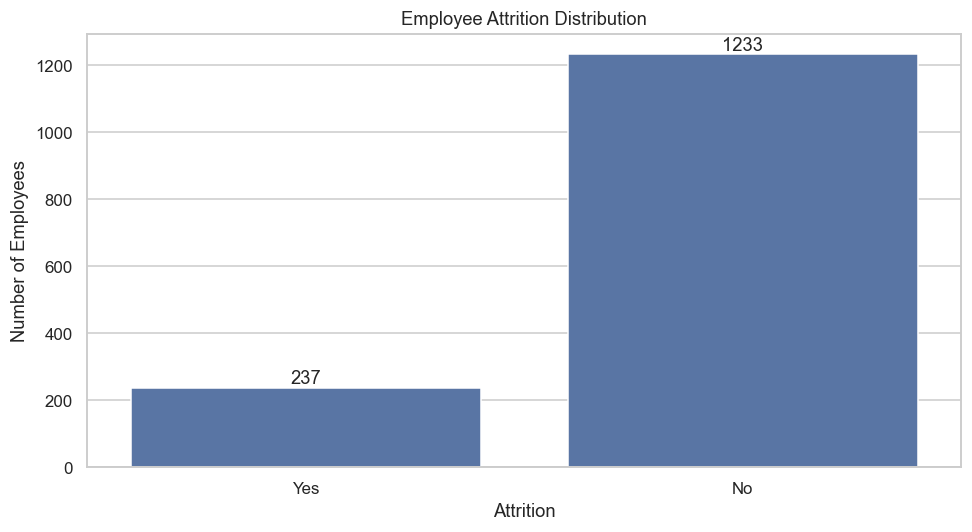

In [11]:
attrition_counts = df["Attrition"].value_counts()

print(attrition_counts)
print("\nPercentage distribution:")
display(
    (df["Attrition"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

ax = sns.countplot(data=df, x="Attrition")
ax.set_title("Employee Attrition Distribution")
ax.set_xlabel("Attrition")
ax.set_ylabel("Number of Employees")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "attrition_distribution.png", bbox_inches="tight")
plt.show()

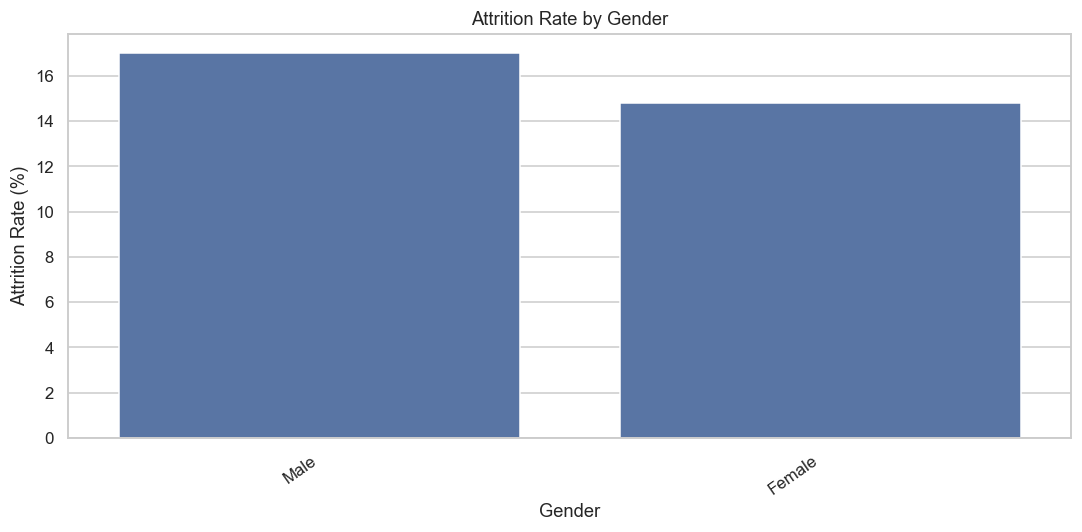

,Attrition Rate (%)
Gender,
Male,17.01
Female,14.80


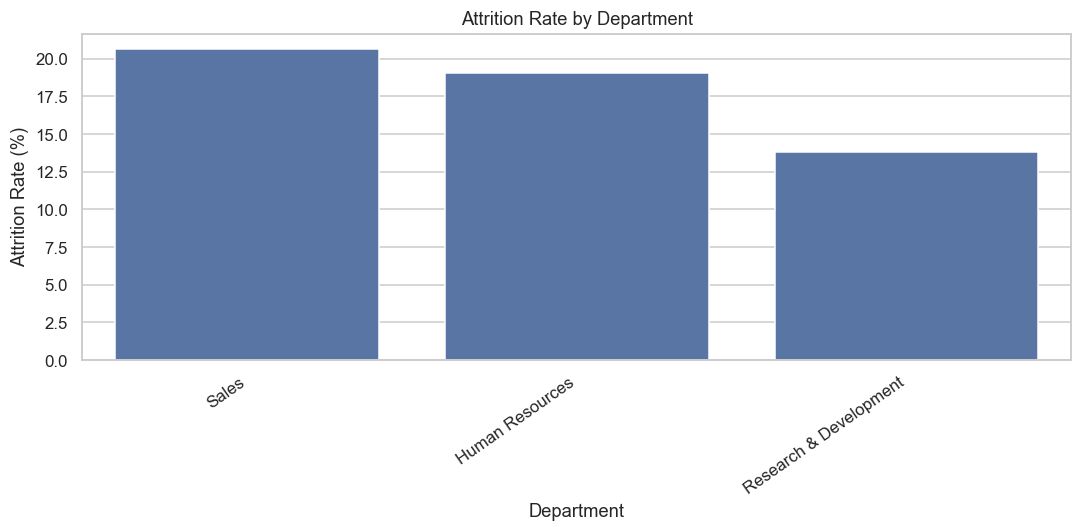

,Attrition Rate (%)
Department,
Sales,20.63
Human Resources,19.05
Research & Development,13.84


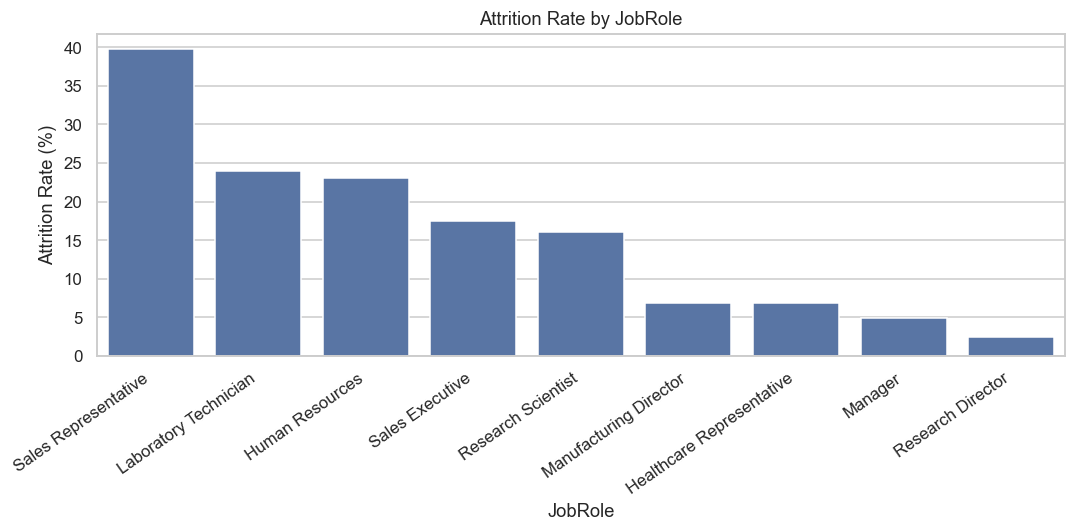

,Attrition Rate (%)
JobRole,
Sales Representative,39.76
Laboratory Technician,23.94
Human Resources,23.08
Sales Executive,17.48
Research Scientist,16.10
Manufacturing Director,6.90
Healthcare Representative,6.87
Manager,4.90
Research Director,2.50


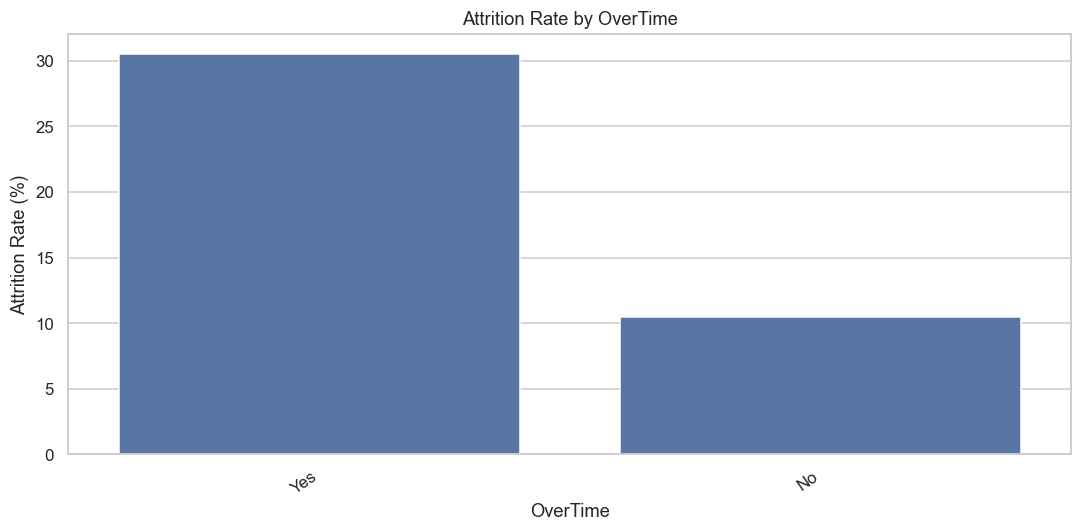

,Attrition Rate (%)
OverTime,
Yes,30.53
No,10.44


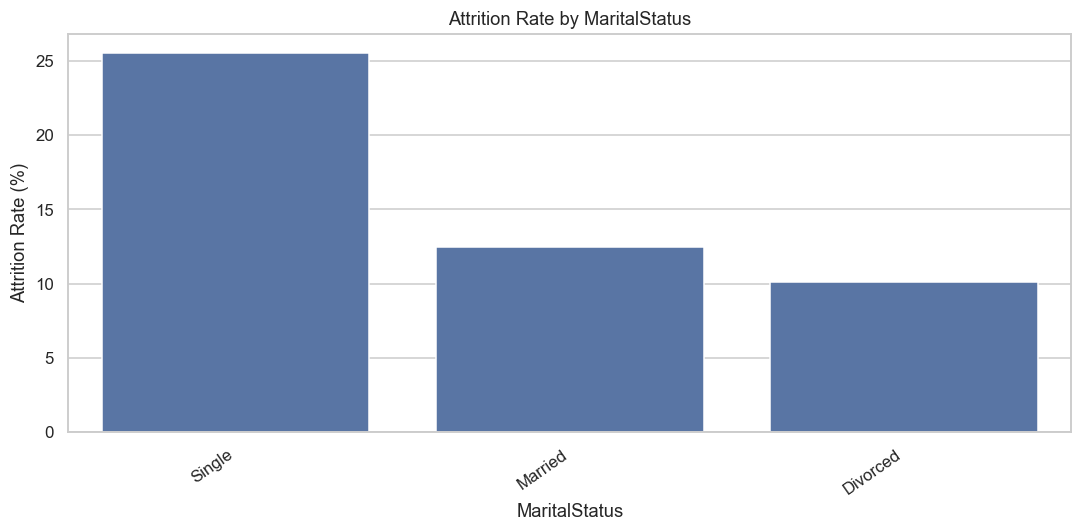

,Attrition Rate (%)
MaritalStatus,
Single,25.53
Married,12.48
Divorced,10.09


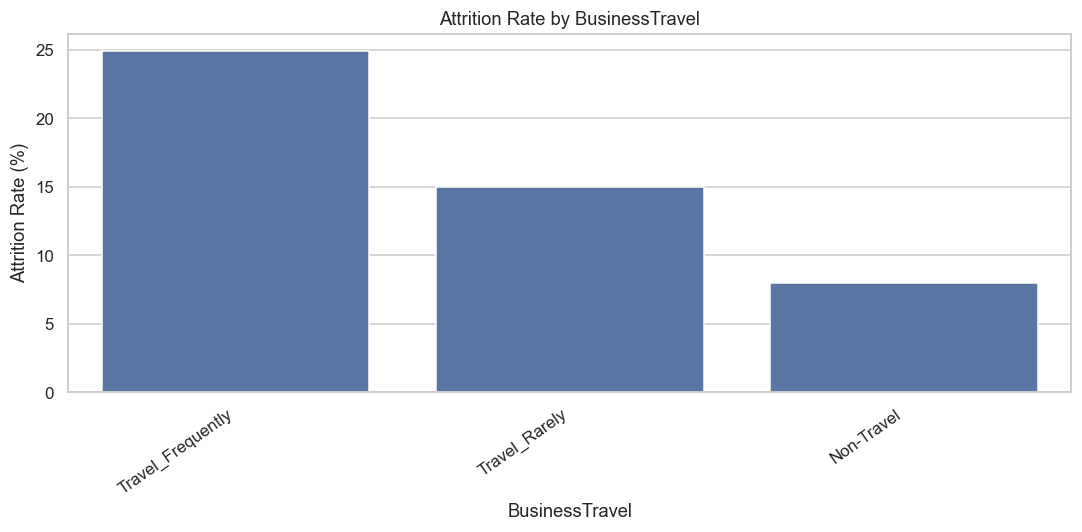

,Attrition Rate (%)
BusinessTravel,
Travel_Frequently,24.91
Travel_Rarely,14.96
Non-Travel,8.00


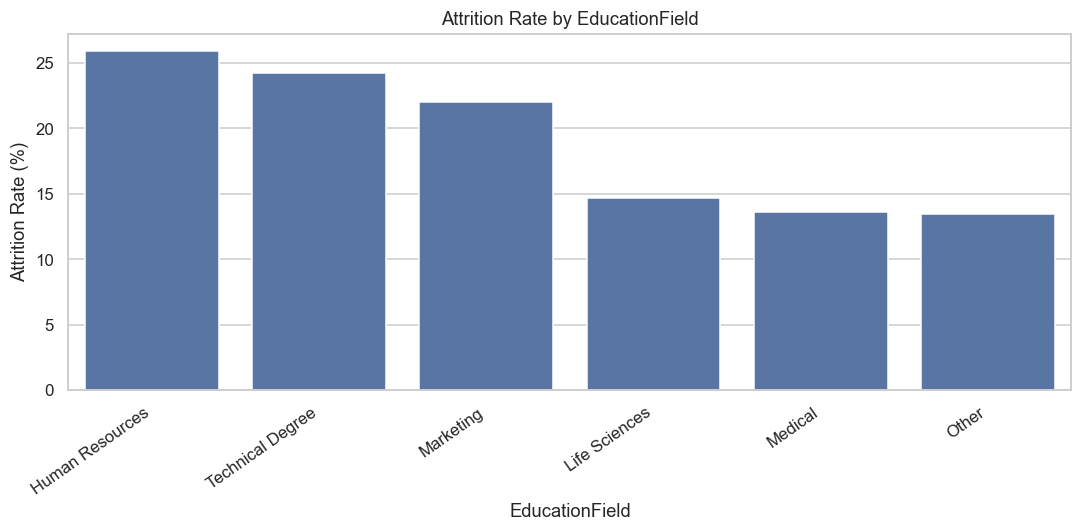

,Attrition Rate (%)
EducationField,
Human Resources,25.93
Technical Degree,24.24
Marketing,22.01
Life Sciences,14.69
Medical,13.58
Other,13.41


In [13]:
categorical_features = [
    "Gender",
    "Department",
    "JobRole",
    "OverTime",
    "MaritalStatus",
    "BusinessTravel",
    "EducationField"
]

for col in categorical_features:
    rates = (
        df.groupby(col, observed=True)["Attrition"]
          .apply(lambda s: (s == "Yes").mean() * 100)
          .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))
    ax = sns.barplot(x=rates.index, y=rates.values)

    ax.set_title(f"Attrition Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Attrition Rate (%)")
    plt.xticks(rotation=35, ha="right")

    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"attrition_by_{col.lower()}.png",
                bbox_inches="tight")
    plt.show()

    display(rates.round(2).to_frame("Attrition Rate (%)"))

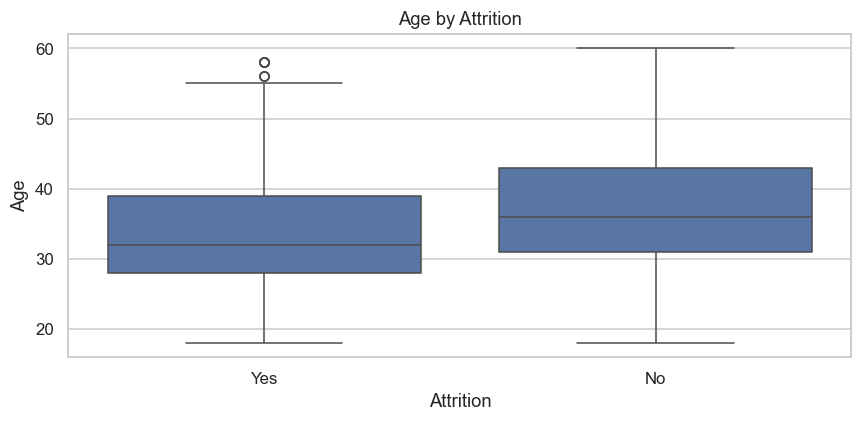

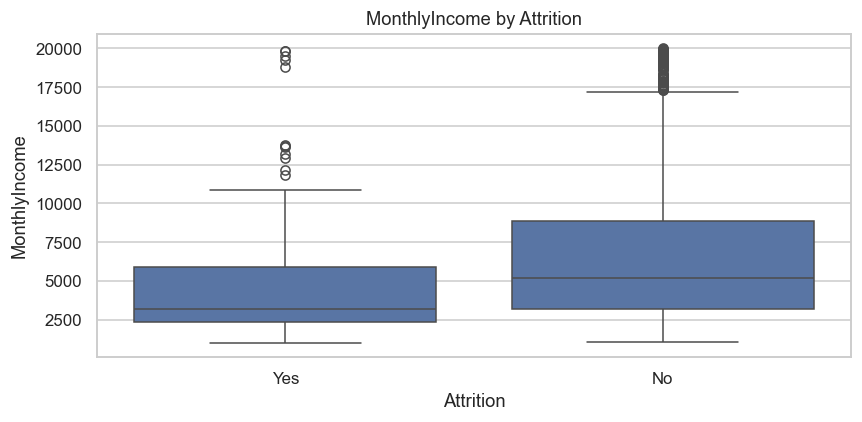

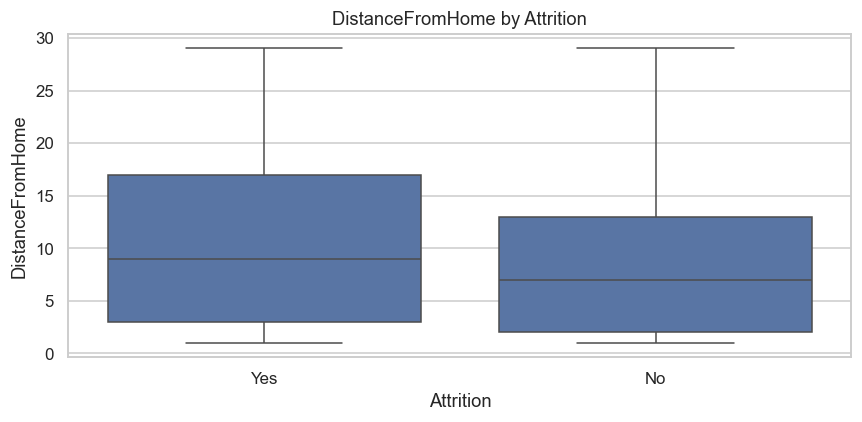

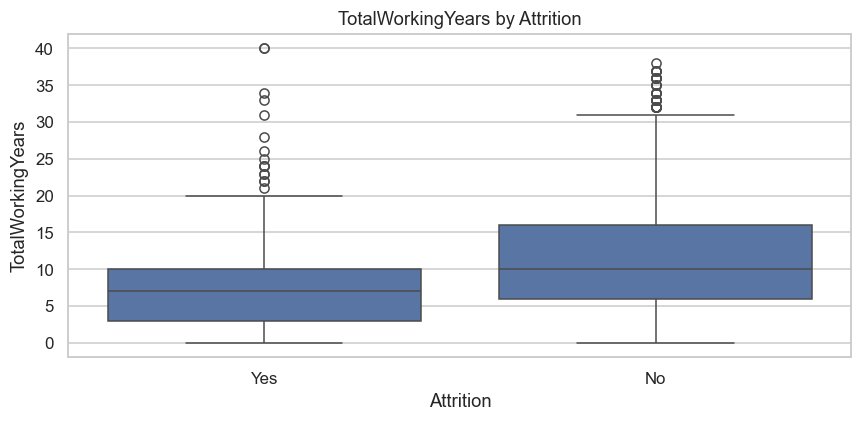

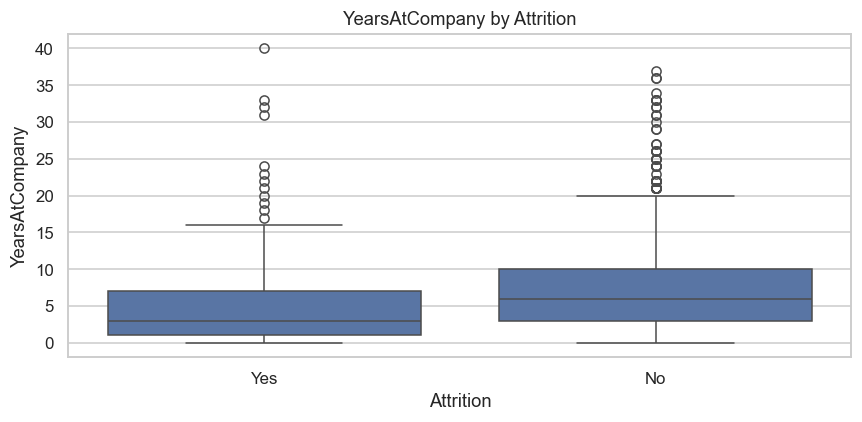

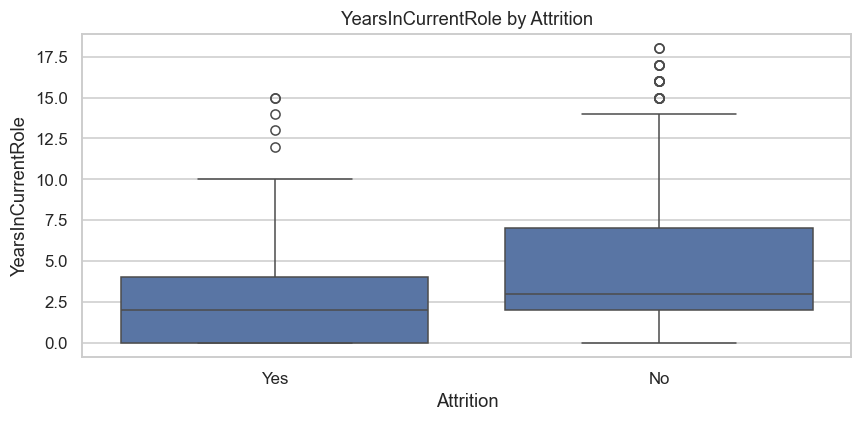

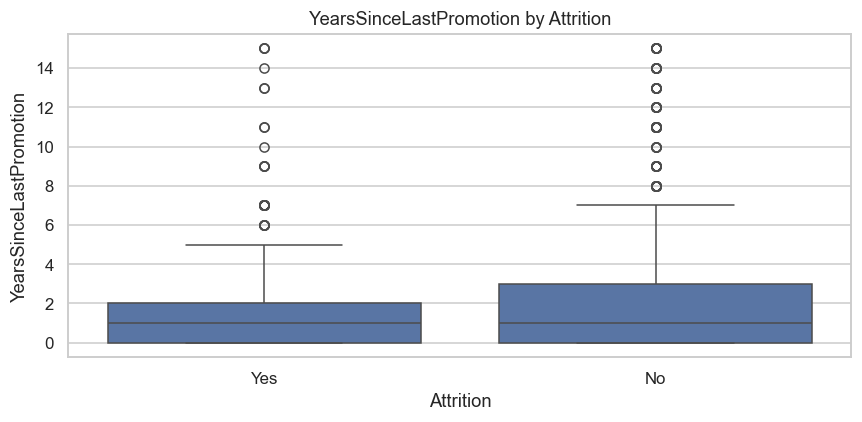

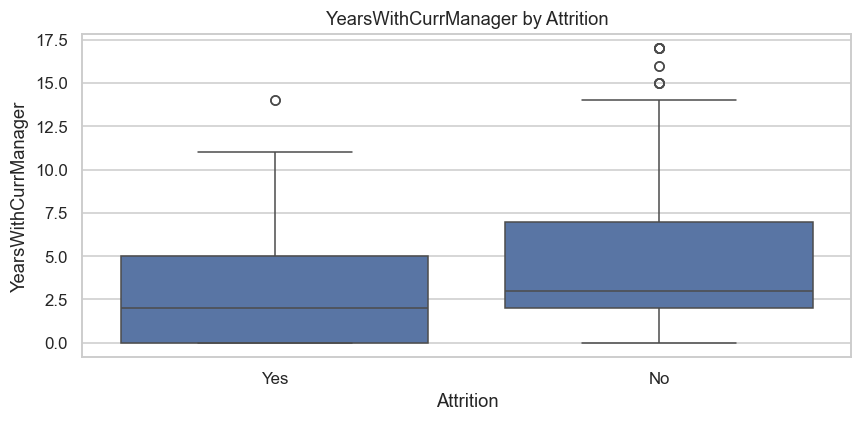

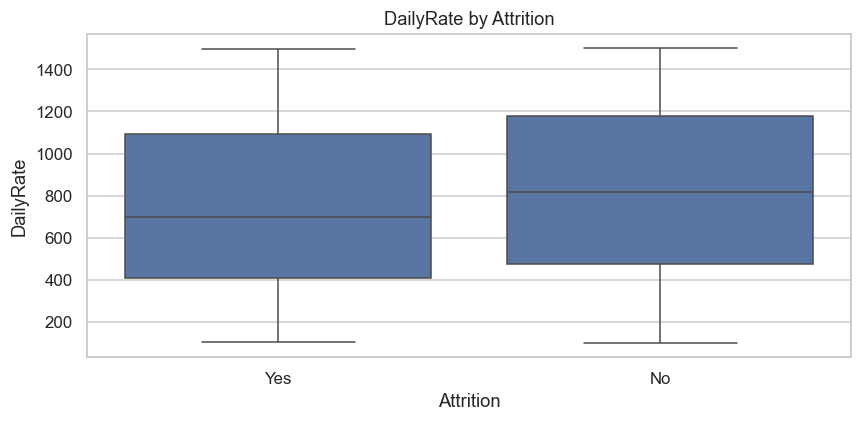

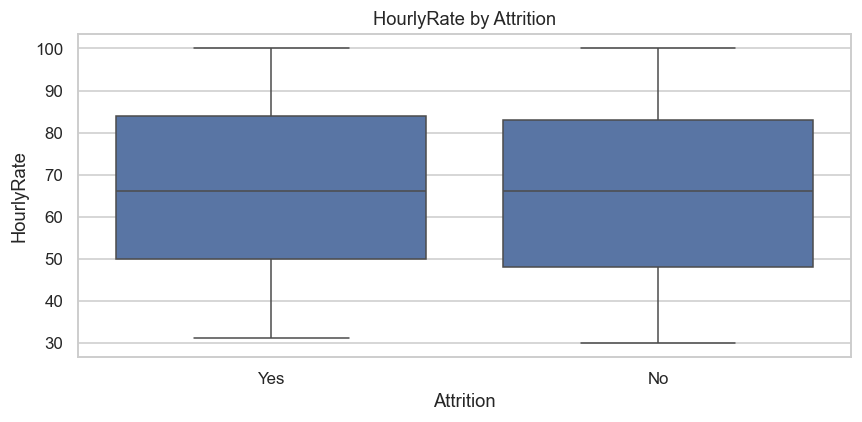

In [15]:
numerical_features = [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager",
    "DailyRate",
    "HourlyRate"
]

for col in numerical_features:
    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x="Attrition", y=col)

    plt.title(f"{col} by Attrition")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"boxplot_{col.lower()}.png",
                bbox_inches="tight")
    plt.show()

Attrition,No,Yes
JobSatisfaction,,
1,77.16,22.84
2,83.57,16.43
3,83.48,16.52
4,88.67,11.33


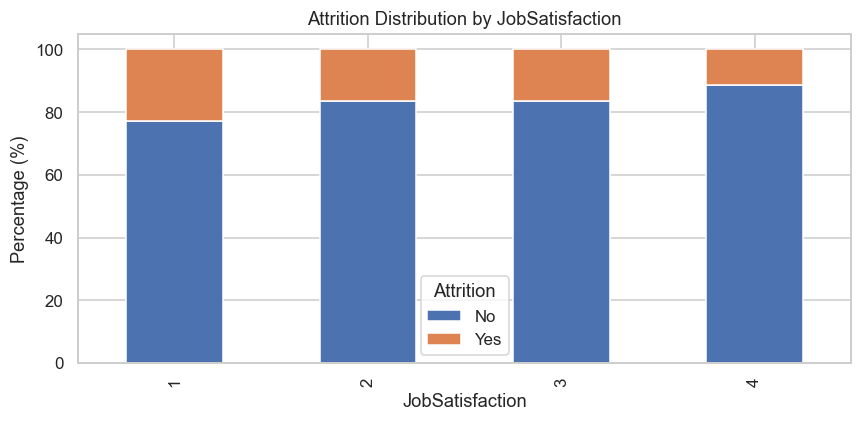

Attrition,No,Yes
EnvironmentSatisfaction,,
1,74.65,25.35
2,85.02,14.98
3,86.31,13.69
4,86.55,13.45


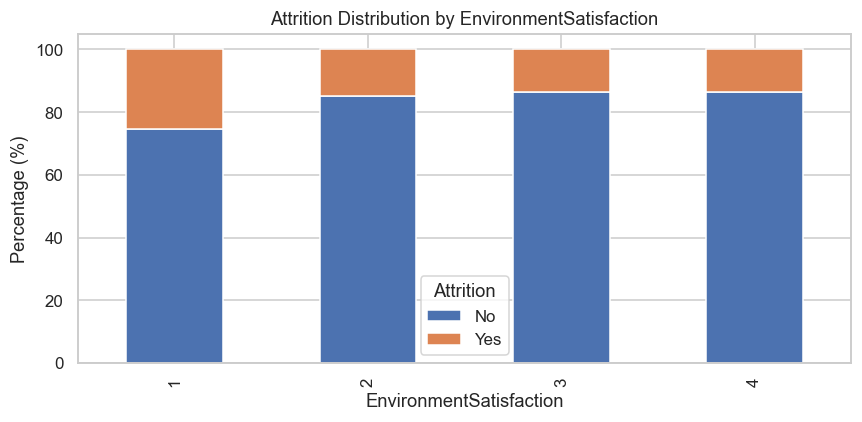

Attrition,No,Yes
RelationshipSatisfaction,,
1,79.35,20.65
2,85.15,14.85
3,84.53,15.47
4,85.19,14.81


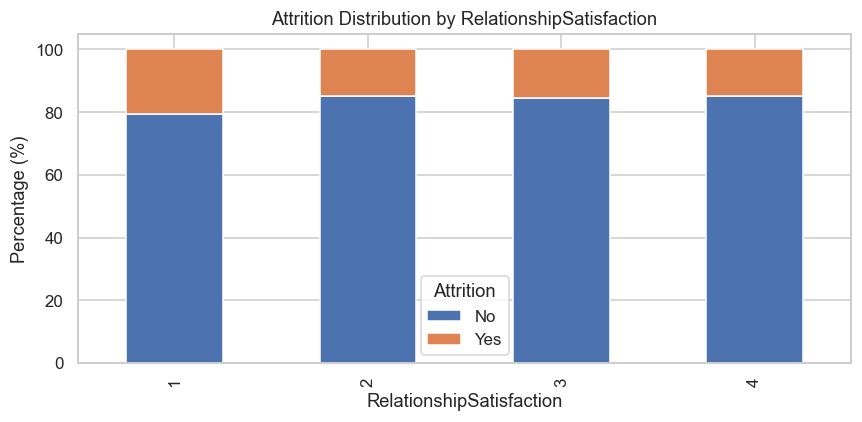

Attrition,No,Yes
WorkLifeBalance,,
1,68.75,31.25
2,83.14,16.86
3,85.78,14.22
4,82.35,17.65


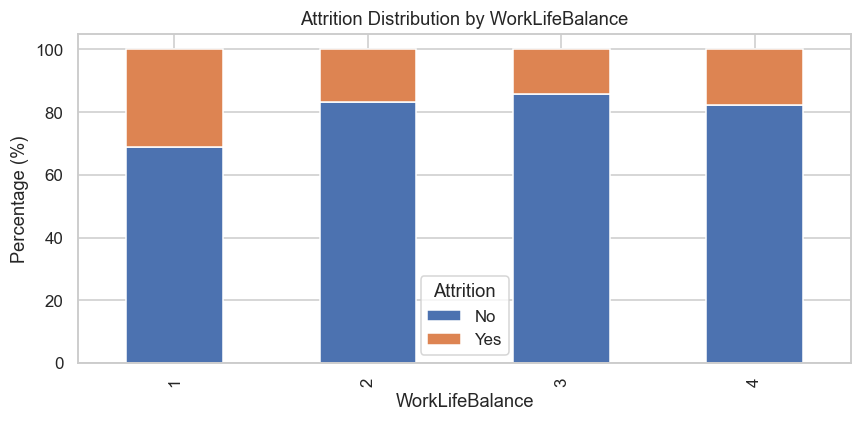

Attrition,No,Yes
JobInvolvement,,
1,66.27,33.73
2,81.07,18.93
3,85.60,14.40
4,90.97,9.03


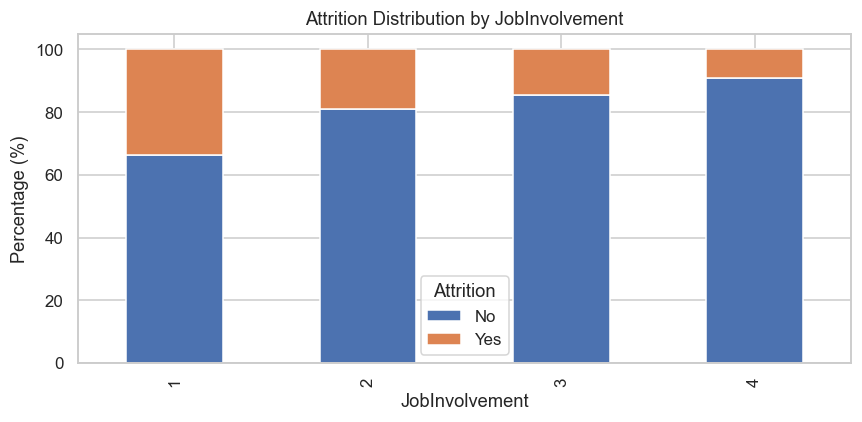

In [17]:
ordinal_features = [
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "RelationshipSatisfaction",
    "WorkLifeBalance",
    "JobInvolvement"
]

for col in ordinal_features:
    rate_table = pd.crosstab(
        df[col],
        df["Attrition"],
        normalize="index"
    ) * 100

    display(rate_table.round(2))

    rate_table.plot(kind="bar", stacked=True, figsize=(8, 4))
    plt.title(f"Attrition Distribution by {col}")
    plt.xlabel(col)
    plt.ylabel("Percentage (%)")
    plt.legend(title="Attrition")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"distribution_{col.lower()}.png",
                bbox_inches="tight")
    plt.show()

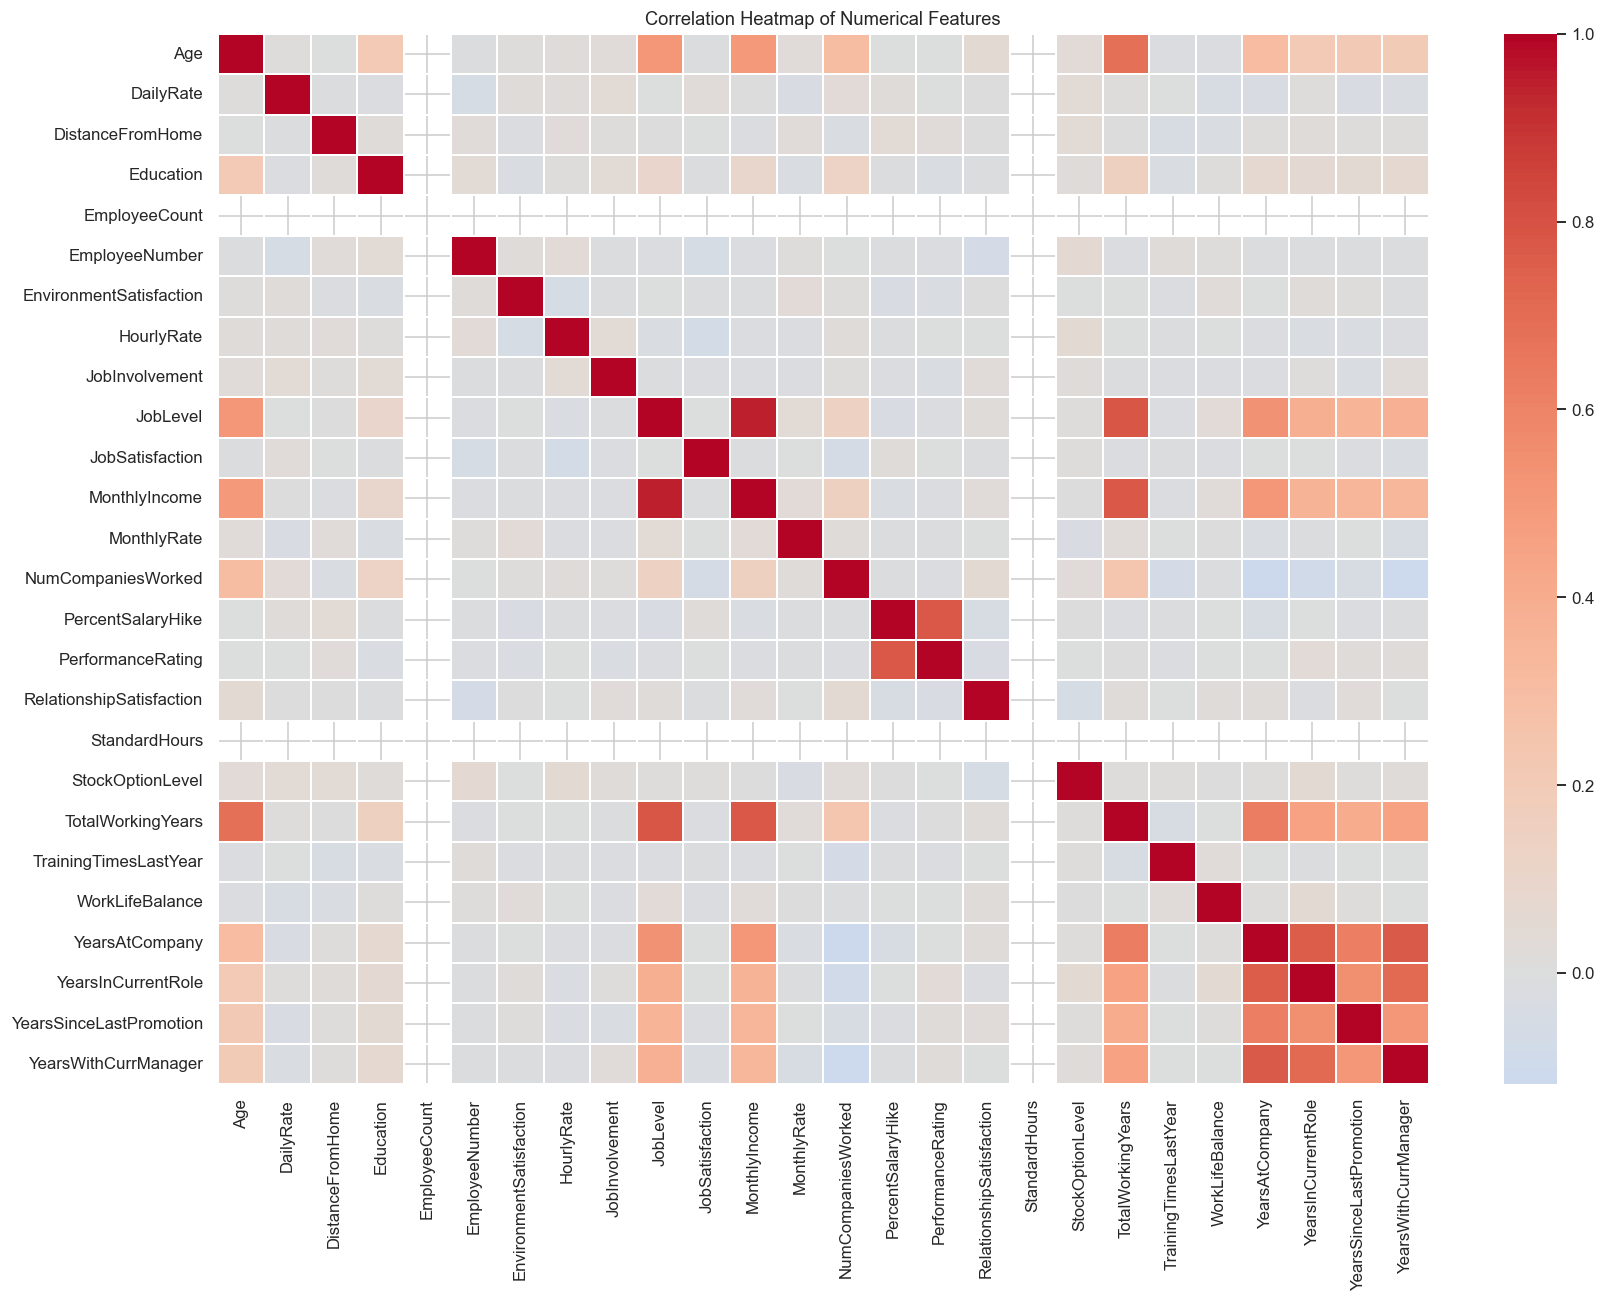

In [19]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(16, 12))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [21]:
overall_rate = (df["Attrition"] == "Yes").mean() * 100

print(f"Overall attrition rate: {overall_rate:.2f}%")

for col in ["Department", "JobRole", "Gender", "OverTime"]:
    rates = (
        df.groupby(col, observed=True)["Attrition"]
          .apply(lambda s: (s == "Yes").mean() * 100)
          .sort_values(ascending=False)
    )

    print(f"\nAttrition rates by {col}:")
    print(rates.round(2))

Overall attrition rate: 16.12%

Attrition rates by Department:
Department
Sales                     20.63
Human Resources           19.05
Research & Development    13.84
Name: Attrition, dtype: float64

Attrition rates by JobRole:
JobRole
Sales Representative         39.76
Laboratory Technician        23.94
Human Resources              23.08
Sales Executive              17.48
Research Scientist           16.10
Manufacturing Director        6.90
Healthcare Representative     6.87
Manager                       4.90
Research Director             2.50
Name: Attrition, dtype: float64

Attrition rates by Gender:
Gender
Male      17.01
Female    14.80
Name: Attrition, dtype: float64

Attrition rates by OverTime:
OverTime
Yes    30.53
No     10.44
Name: Attrition, dtype: float64
